# Larsen (2024) PdAg semihydrogenation benchmark

This notebook reconstructs the steady-state reactor model and the selected experimental curves reported by Victor Larsen, *Semihydrogenation of acetylene to ethylene with a PdAg catalyst* (TU Delft BEP, June 2024).

The dataset contains exact Pd₀Ag response values transcribed from the Appendix F comparison table and marker-center digitizations for Pd₂Ag and Pd₃Ag from Figures 6.1–6.4. Those categories are flagged separately in the CSV. The thesis reports all-experiment overall RMSE values of 5.0962, 5.4320, and 7.1353 percentage points for Pd₀Ag, Pd₂Ag, and Pd₃Ag, respectively. The selected-curve calculation below is a partial-data check; it does not reproduce those all-experiment metrics.

Source correction: Tables E.1–E.3 compare standard LHHW model variants. The complete eight-parameter vectors used here are printed above the parity plots in Figure 6.6 (printed thesis p. 38). The experimental trends are in Figures 6.1–6.4 and Appendix A. Appendices B–D contain simulated trends. Larsen studied H₂/C₂H₂/C₂H₄ feeds diluted with He; CO is not part of these experiments or this model.

## Source and data handling

Appendix F shows a 41-row experiment table for Pd₀Ag and a comparison table with measured conversion and selectivity. The plotted multi-catalyst curves in Figures 6.1–6.4 are used for Pd₂Ag and Pd₃Ag because the thesis does not print their full raw response tables. Digitized responses are rounded estimates with a stated ±2 percentage-point reading uncertainty; feed composition and x-axis values come from the plotted conditions and the thesis tables.

Reported reactor inputs are 100 °C and 1000 mbar. Catalyst masses are 100, 75, and 100 mg for Pd₀Ag, Pd₂Ag, and Pd₃Ag. Appendix F gives a 0.5 cm tube diameter and a support density of 2.65 g cm⁻³. The catalyst-bed length is derived as catalyst mass divided by support density and tube area. He is set by feed balance. The final parameter pressure basis is interpreted as Pa and the rate basis as mol kg-cat⁻¹ s⁻¹; this interpretation is consistent with the printed values and the Appendix F reactor normalization.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display

data_dir = Path("data")
curve_data = pd.read_csv(data_dir / "larsen_2024_selected_curves.csv")
parameters = pd.read_csv(data_dir / "larsen_2024_parameters.csv").set_index("catalyst")

assert len(curve_data) == 45
assert np.allclose(
    curve_data[["feed_C2H2_vol_pct", "feed_C2H4_vol_pct", "feed_H2_vol_pct", "feed_He_vol_pct"]].sum(axis=1),
    100.0,
)
display(parameters[["k1", "k2", "r1_max", "K_C2H2", "K_H2", "K_C2H4", "K_inh", "n_inh",
                   "published_overall_rmse_pct_points", "n_experiments"]])
curve_data.groupby(["catalyst", "response_origin"]).size().rename("rows").to_frame()

,k1,k2,r1_max,K_C2H2,K_H2,K_C2H4,K_inh,n_inh,published_overall_rmse_pct_points,n_experiments
catalyst,,,,,,,,,,
Pd0Ag,6.470000e+12,9.020000e+11,0.007809,0.002407,1.820000e-19,1.800000e-05,0.000000e+00,-1966.78000,5.0962,41
Pd2Ag,6.829250e+00,7.939600e-01,0.014413,0.001891,1.170000e-06,9.930000e-06,1.890000e-07,10.59270,5.4320,42
Pd3Ag,6.707880e+02,5.785400e+02,0.038340,0.000048,2.378000e-07,8.709000e-08,1.176000e-04,4.89665,7.1353,41


,,rows
catalyst,response_origin,
Pd0Ag,exact_appendix_F_table,15
Pd2Ag,visual_digitization,15
Pd3Ag,visual_digitization,15


## Differential reactor model

For species flows \(F_i\), the axial balances are

\[
\frac{dF_{C_2H_2}}{dz}=-\rho A r_1,\quad
\frac{dF_{C_2H_4}}{dz}=\rho A(r_1-r_2),\quad
\frac{dF_{C_2H_6}}{dz}=\rho A r_2,
\]
\[
\frac{dF_{H_2}}{dz}=-\rho A(r_1+r_2),\qquad
\frac{dF_{He}}{dz}=0.
\]

The final rate law includes the acetylene-rate cap and fitted inhibition exponent:

\[
r_1^{raw}=\frac{k_1 K_Ap_A K_Hp_H}{(1+K_Ap_A+K_Ep_E+K_Hp_H)^2},\qquad
r_1=\frac{r_1^{raw}}{1+r_1^{raw}/r_{1,max}},
\]
\[
r_2=\frac{k_2K_Ep_EK_Hp_H}{(1+K_Ap_A+K_Ep_E)^2(1+K_{inh}p_A)^{n_{inh}}}.
\]

Partial pressures are calculated from the evolving molar-flow fractions at 100000 Pa. Conversion is \(X=1-F_{A,out}/F_{A,in}\), and selectivity is net ethylene formation divided by acetylene consumed, \(S=(F_{E,out}-F_{E,in})/(F_{A,in}-F_{A,out})\). Selectivity can be negative when feed ethylene is consumed overall. The printed Pd₀Ag parameters have \(K_{inh}=0\) and a large negative \(n_{inh}\); the inhibition factor is therefore exactly one for this catalyst and the exponent is non-identifiable from that vector.

In [2]:
R = 8.314462618  # J mol^-1 K^-1
TEMPERATURE_K = 373.15
TOTAL_PRESSURE_PA = 100_000.0
TUBE_DIAMETER_M = 0.005
SUPPORT_DENSITY_KG_M3 = 2650.0
TUBE_AREA_M2 = np.pi * TUBE_DIAMETER_M**2 / 4.0
CATALYST_ORDER = ["Pd0Ag", "Pd2Ag", "Pd3Ag"]
COLORS = {"Pd0Ag": "#c99400", "Pd2Ag": "#c44900", "Pd3Ag": "#315c9b"}

def rates_from_flows(flows_mol_s, par):
    flows = np.maximum(np.asarray(flows_mol_s, dtype=float), 0.0)
    total_flow = max(flows.sum(), 1e-30)
    p_a, p_e, _, p_h, _ = flows / total_flow * TOTAL_PRESSURE_PA

    denominator_1 = (1.0 + par.K_C2H2*p_a + par.K_C2H4*p_e + par.K_H2*p_h)**2
    r1_raw = par.k1 * par.K_C2H2*p_a * par.K_H2*p_h / denominator_1
    r1 = r1_raw / (1.0 + r1_raw / par.r1_max)

    inhibition_base = 1.0 + par.K_inh*p_a
    denominator_2 = (1.0 + par.K_C2H2*p_a + par.K_C2H4*p_e)**2 * inhibition_base**par.n_inh
    r2 = par.k2 * par.K_C2H4*p_e * par.K_H2*p_h / denominator_2
    return r1, r2

def simulate_experiment(row):
    par = parameters.loc[row.catalyst]
    inlet_flow_m3_s = row.flow_ml_min * 1e-6 / 60.0
    total_molar_flow = TOTAL_PRESSURE_PA * inlet_flow_m3_s / (R * TEMPERATURE_K)
    feed = total_molar_flow * np.array([
        row.feed_C2H2_vol_pct,
        row.feed_C2H4_vol_pct,
        0.0,
        row.feed_H2_vol_pct,
        row.feed_He_vol_pct,
    ]) / 100.0

    catalyst_mass_kg = row.catalyst_mass_mg * 1e-6
    bed_length_m = catalyst_mass_kg / (SUPPORT_DENSITY_KG_M3 * TUBE_AREA_M2)
    mass_per_length = SUPPORT_DENSITY_KG_M3 * TUBE_AREA_M2

    def rhs(z, flows):
        r1, r2 = rates_from_flows(flows, par)
        return mass_per_length * np.array([-r1, r1-r2, r2, -r1-r2, 0.0])

    result = solve_ivp(
        rhs, (0.0, bed_length_m), feed,
        method="DOP853", rtol=1e-8, atol=1e-15,
    )
    if not result.success:
        raise RuntimeError(f"ODE integration failed for {row.catalyst}, Fig. {row.figure}: {result.message}")

    outlet = np.maximum(result.y[:, -1], 0.0)
    conversion = 100.0 * (1.0 - outlet[0] / feed[0])
    selectivity = 100.0 * (outlet[1] - feed[1]) / (feed[0] - outlet[0])
    return pd.Series({"model_conversion_pct": conversion, "model_selectivity_pct": selectivity,
                      "bed_length_mm": 1000.0 * bed_length_m})

predictions = pd.concat([curve_data, curve_data.apply(simulate_experiment, axis=1)], axis=1)
predictions[["catalyst", "figure", "independent_variable", "independent_value",
             "conversion_pct", "model_conversion_pct", "selectivity_pct", "model_selectivity_pct"]].head()

,catalyst,figure,independent_variable,independent_value,conversion_pct,model_conversion_pct,selectivity_pct,model_selectivity_pct
0,Pd0Ag,6.1,GHSV,120000,10.462575,25.005780,99.716055,96.317219
1,Pd0Ag,6.1,GHSV,90000,20.991291,33.483644,98.858475,96.084272
2,Pd0Ag,6.1,GHSV,60000,41.147780,50.476081,98.759846,95.487799
3,Pd0Ag,6.1,GHSV,30000,89.976409,93.085128,94.960679,91.223601
4,Pd2Ag,6.1,GHSV,160000,58.000000,68.862415,95.000000,93.231585


In [3]:
# Keep the measured and model values together for a compact audit trail.
predictions.assign(
    conversion_error_pct_points=predictions.model_conversion_pct-predictions.conversion_pct,
    selectivity_error_pct_points=predictions.model_selectivity_pct-predictions.selectivity_pct,
)[["catalyst", "figure", "independent_value", "conversion_pct", "model_conversion_pct",
   "selectivity_pct", "model_selectivity_pct", "response_origin"]].round(2)

,catalyst,figure,independent_value,conversion_pct,model_conversion_pct,selectivity_pct,model_selectivity_pct,response_origin
0,Pd0Ag,6.1,120000,10.46,25.01,99.72,96.32,exact_appendix_F_table
1,Pd0Ag,6.1,90000,20.99,33.48,98.86,96.08,exact_appendix_F_table
2,Pd0Ag,6.1,60000,41.15,50.48,98.76,95.49,exact_appendix_F_table
3,Pd0Ag,6.1,30000,89.98,93.09,94.96,91.22,exact_appendix_F_table
4,Pd2Ag,6.1,160000,58.00,68.86,95.00,93.23,visual_digitization
5,Pd2Ag,6.1,120000,87.00,89.15,94.00,90.92,visual_digitization
6,Pd2Ag,6.1,80000,100.00,99.99,85.00,80.84,visual_digitization
7,Pd2Ag,6.1,40000,99.00,100.00,56.00,45.95,visual_digitization
8,Pd3Ag,6.1,120000,99.00,99.99,69.00,60.80,visual_digitization
9,Pd3Ag,6.1,90000,99.00,100.00,56.00,46.28,visual_digitization


## Curves and model overlays

The markers show thesis values or digitized chart estimates; dashed open markers show the integrated model at the same feed conditions. Figure 6.1 uses mass-normalized GHSV. Figures 6.2–6.4 use the varied reactant partial pressure in mbar.

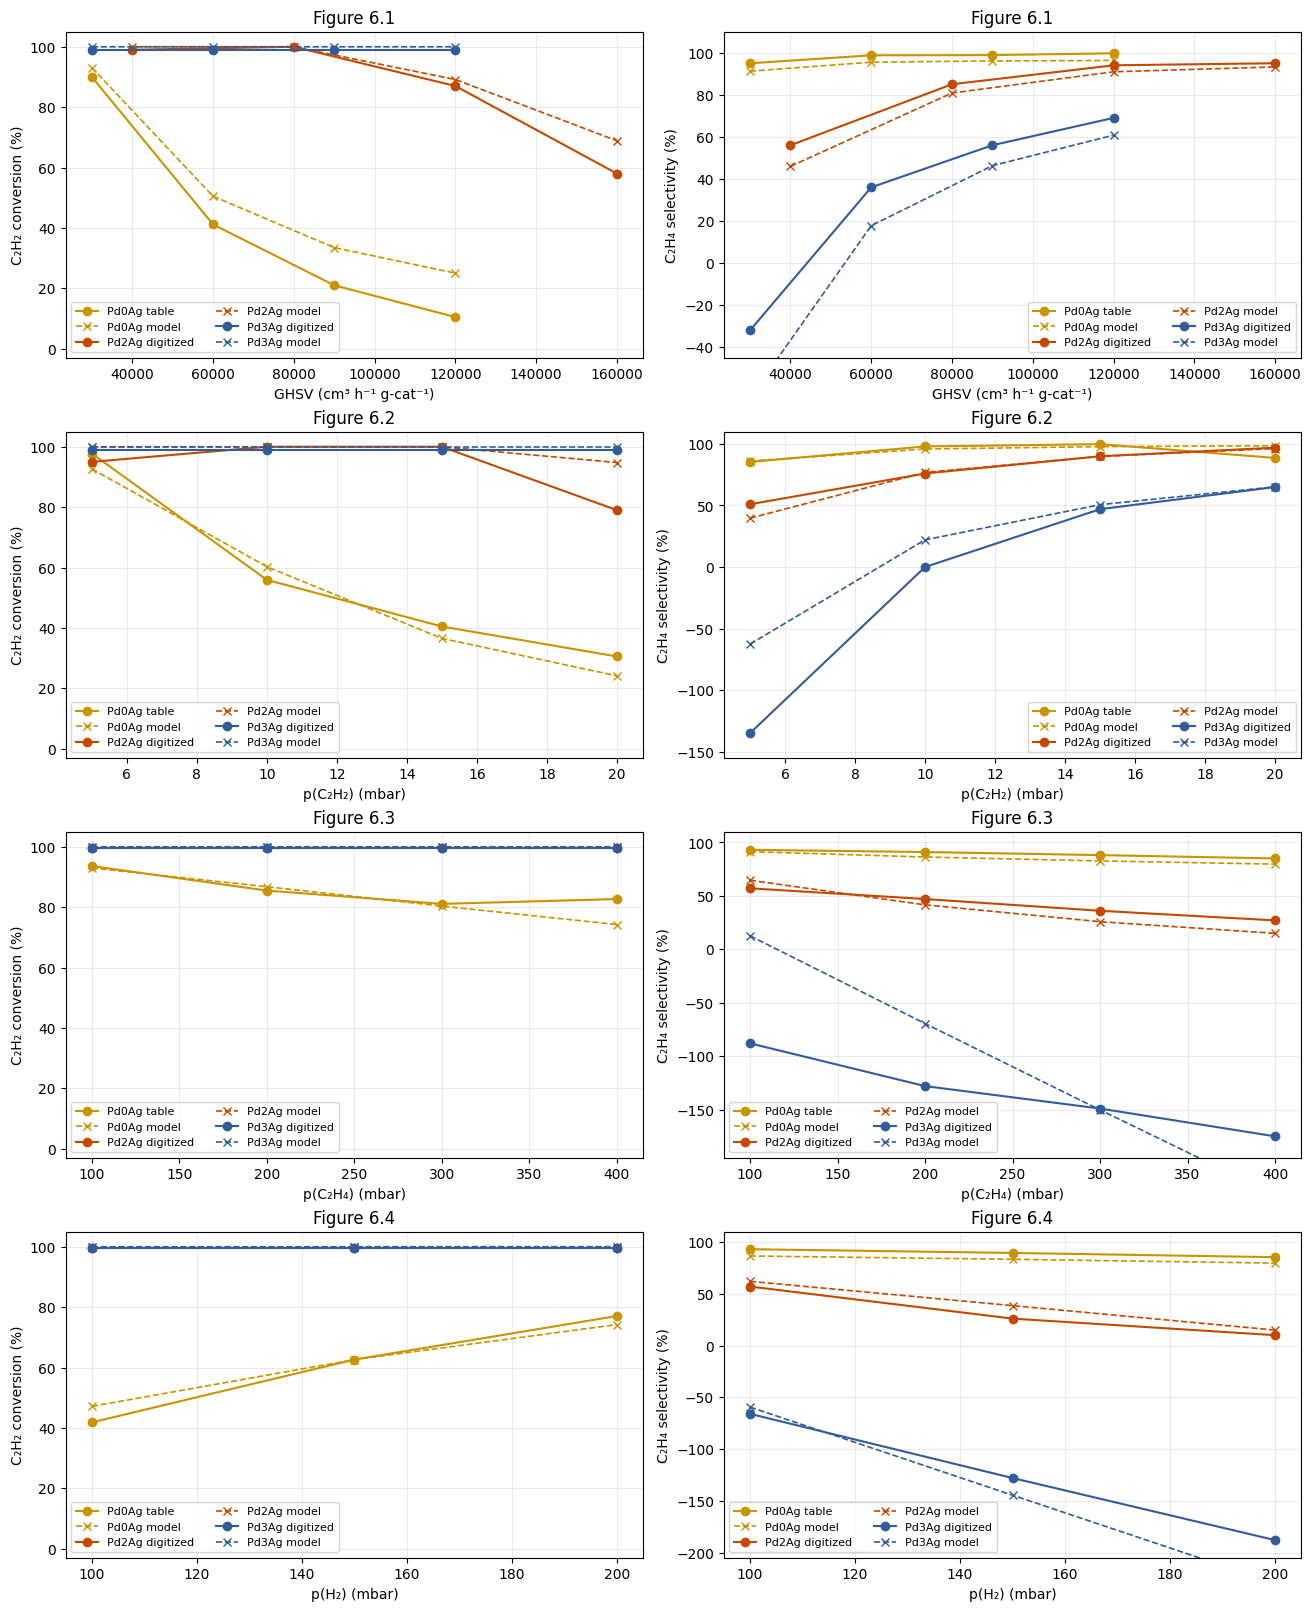

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(13, 16), constrained_layout=True)
figure_specs = {
    6.1: ("GHSV (cm³ h⁻¹ g-cat⁻¹)", "flow"),
    6.2: ("p(C₂H₂) (mbar)", "acetylene"),
    6.3: ("p(C₂H₄) (mbar)", "ethylene"),
    6.4: ("p(H₂) (mbar)", "hydrogen"),
}

for row_idx, (figure_no, (xlabel, _series)) in enumerate(figure_specs.items()):
    subset = predictions[predictions.figure == figure_no]
    for col_idx, (measured, modeled, ylabel) in enumerate([
        ("conversion_pct", "model_conversion_pct", "C₂H₂ conversion (%)"),
        ("selectivity_pct", "model_selectivity_pct", "C₂H₄ selectivity (%)"),
    ]):
        ax = axes[row_idx, col_idx]
        for catalyst in CATALYST_ORDER:
            cat_data = subset[subset.catalyst == catalyst].sort_values("independent_value")
            x = cat_data.independent_value.to_numpy()
            color = COLORS[catalyst]
            source_label = "table" if cat_data.response_origin.iloc[0] == "exact_appendix_F_table" else "digitized"
            ax.plot(x, cat_data[measured], color=color, marker="o", linewidth=1.5,
                    label=f"{catalyst} {source_label}")
            ax.plot(x, cat_data[modeled], color=color, marker="x", linestyle="--",
                    linewidth=1.2, label=f"{catalyst} model")
        ax.set_title(f"Figure {figure_no:.1f}")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8, ncol=2)
        if col_idx == 0:
            ax.set_ylim(-3, 105)
        else:
            y_min = {6.1: -45, 6.2: -155, 6.3: -195, 6.4: -205}[figure_no]
            ax.set_ylim(y_min, 110)

plt.show()

## Selected-curve errors versus published all-experiment values

The thesis defines one combined error per experiment as the root mean square of its conversion and selectivity errors, then averages those experiment errors. This notebook uses the same paired calculation on the 15 selected points per catalyst. The published benchmark uses all 41/42/41 experiments and is reported separately for context.

In [5]:
def paired_experiment_rmse(frame):
    conversion_error = frame.model_conversion_pct - frame.conversion_pct
    selectivity_error = frame.model_selectivity_pct - frame.selectivity_pct
    return np.sqrt((conversion_error**2 + selectivity_error**2) / 2.0)

predictions["paired_experiment_rmse_pct_points"] = paired_experiment_rmse(predictions)
metrics = []
for catalyst in CATALYST_ORDER:
    part = predictions[predictions.catalyst == catalyst]
    par = parameters.loc[catalyst]
    metrics.append({
        "catalyst": catalyst,
        "selected_points": len(part),
        "selected_paired_rmse_pct_points": part.paired_experiment_rmse_pct_points.mean(),
        "selected_conversion_rmse_pct_points": np.sqrt(np.mean((part.model_conversion_pct-part.conversion_pct)**2)),
        "selected_selectivity_rmse_pct_points": np.sqrt(np.mean((part.model_selectivity_pct-part.selectivity_pct)**2)),
        "published_all_experiment_rmse_pct_points": par.published_overall_rmse_pct_points,
        "published_experiment_count": int(par.n_experiments),
    })

metrics = pd.DataFrame(metrics).set_index("catalyst")
metrics.round(3)

,selected_points,selected_paired_rmse_pct_points,selected_conversion_rmse_pct_points,selected_selectivity_rmse_pct_points,published_all_experiment_rmse_pct_points,published_experiment_count
catalyst,,,,,,
Pd0Ag,15,5.268,6.713,4.806,5.096,41
Pd2Ag,15,5.470,5.157,7.324,5.432,42
Pd3Ag,15,21.081,0.806,41.482,7.135,41


The selected-point errors should not be read as a recalculation of the thesis-wide RMSE. The thesis does not provide full raw response tables for Pd₂Ag and Pd₃Ag, and the digitized plotted values carry reading uncertainty. The published all-experiment RMSE values are retained exactly as reported in Figure 6.6. Recovering an exact independent check of those values requires the underlying experiment workbook or full per-catalyst measured table.

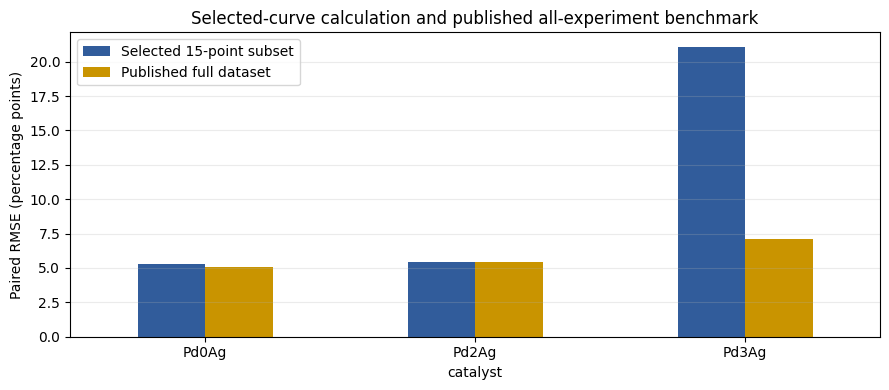

In [6]:
ax = metrics[["selected_paired_rmse_pct_points", "published_all_experiment_rmse_pct_points"]].plot(
    kind="bar", figsize=(9, 4), color=["#315c9b", "#c99400"]
)
ax.set_ylabel("Paired RMSE (percentage points)")
ax.set_title("Selected-curve calculation and published all-experiment benchmark")
ax.legend(["Selected 15-point subset", "Published full dataset"])
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Reproducibility notes

- Parameter vectors and published full-dataset RMSE values are transcribed from Figure 6.6.
- The rate-law implementation includes all eight parameters, including \(r_{1,max}\) and \(n_{inh}\).
- Feed species are C₂H₂, C₂H₄, H₂, and He. No CO term is used.
- Exact Pd₀Ag values and digitized Pd₂Ag/Pd₃Ag values are identifiable in `data/larsen_2024_selected_curves.csv` through `response_origin` and `digitization_uncertainty_pp`.
- Parameter and geometry units are interpreted on an SI basis to reproduce the thesis model scale; the thesis screenshots do not print a complete formal unit table for every fitted kinetic coefficient.